# Time series analysis
## Project 2026

## Environment setup

In [45]:
from tsa_lth.analysis import plotACFnPACF, box_cox
from tsa_lth.modelling import estimateARMA, polydiv
from tsa_lth.tests import whiteness_test, monti_test
import sys
from scipy.io import loadmat
import scipy.signal
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path("..")
DATA_DIR = PROJECT_ROOT / "data"

sys.path.append("..")
from toolbox.timeseries import TimeSeries, verify_white_and_normal

## Data loading

In [46]:
from dataclasses import dataclass

@dataclass
class ProjectData:
    nederbord: TimeSeries
    temperature: TimeSeries
    time: TimeSeries
    waterflow: TimeSeries

def load_project_data() -> ProjectData:
    project_data_raw = loadmat(DATA_DIR / "projectData26.mat")

    project_data = ProjectData(
        project_data_raw["nbdData"].flatten(),
        project_data_raw["tempData"].flatten(),
        np.arange(0, 2000, 1) / 365,
        # project_data_raw["timeData"],
        project_data_raw["waterflowData"].flatten()
    )

    return project_data

project_data = load_project_data()
print(project_data.time)


[0.00000000e+00 2.73972603e-03 5.47945205e-03 ... 5.47123288e+00
 5.47397260e+00 5.47671233e+00]


# Analysis

## Initial model creation

### Transforms

First we plot the initial data, in order to eyeball the properties of the dataset.

Text(0, 0.5, '$m^3/s$')

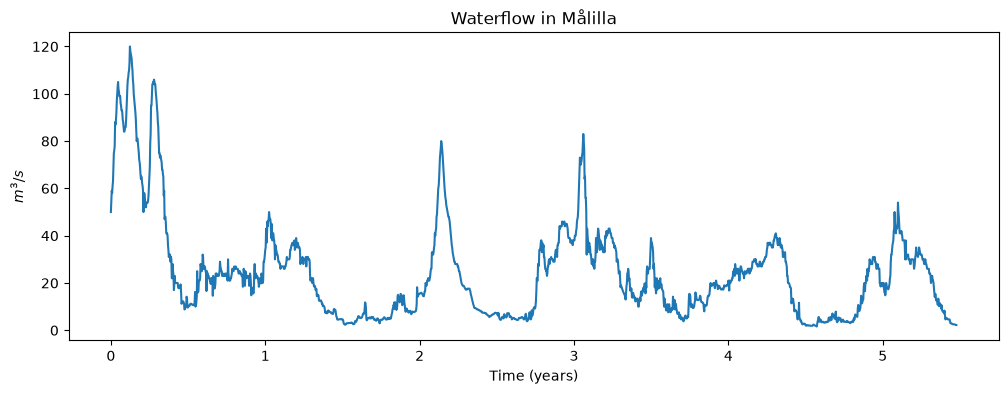

In [47]:
plt.figure(figsize=(12, 4))
plt.plot(project_data.time, project_data.waterflow)
plt.title("Waterflow in Målilla")
plt.xlabel("Time (years)")
plt.ylabel("$m^3/s$")

Clearly the process is not stationary. Can we transform it in some way to amend this?

- Clearly subtracting some linear or periodic trend is not suitable. There seems to be no set period, nor  a clear trend.
- The variance is different for different parts of the process. Perhaps we could look at a transform. 
- The data seems to deviate from the mean quite often. A differentiation seems like an apt first tool to try.

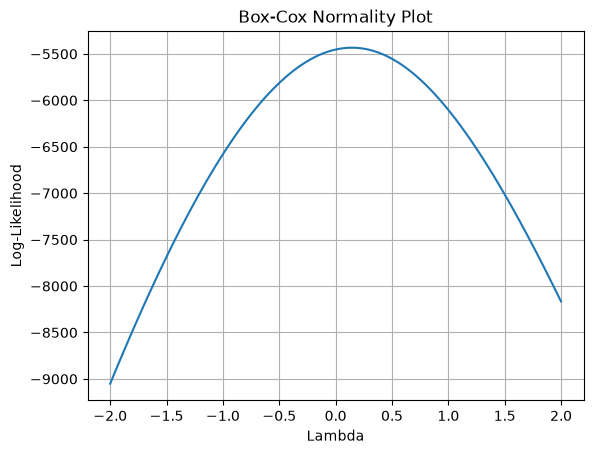

Max Lambda = 0.14454982772227937.
ln(y) could be an appropriate transformation.


In [48]:
box_cox(project_data.waterflow)

It seems like we might need a transform after all...
We try with the log

Text(0.5, 0, 'Time (years)')

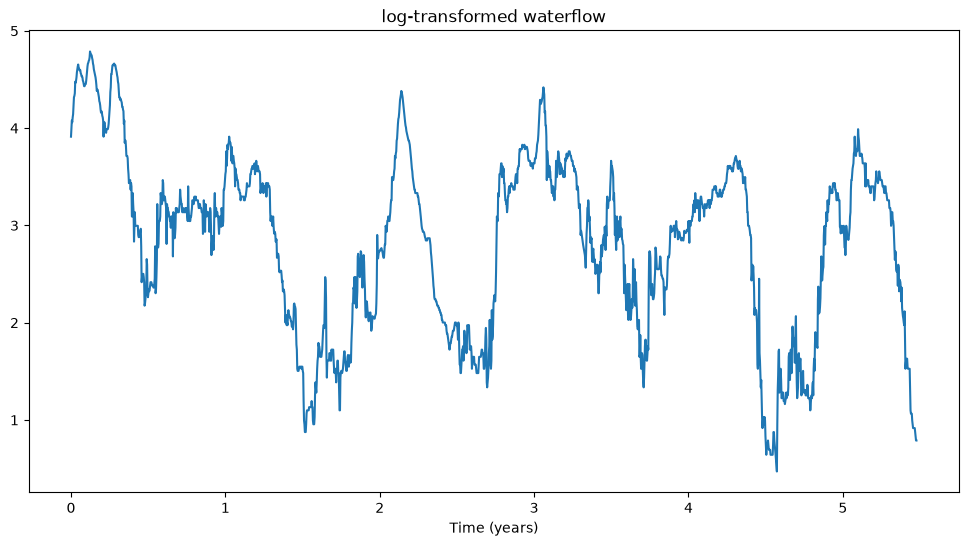

In [49]:
log_waterflow = np.log(project_data.waterflow)

plt.figure(figsize=(12, 6))
plt.plot(project_data.time, log_waterflow)
plt.title("log-transformed waterflow")
plt.xlabel("Time (years)")

## Modelling

Okay, the dataset looks a bit more manageable now. We start modelling, starting easy by taking the first 4 weeks.

Text(0.5, 1.0, 'Differentiated waterflow')

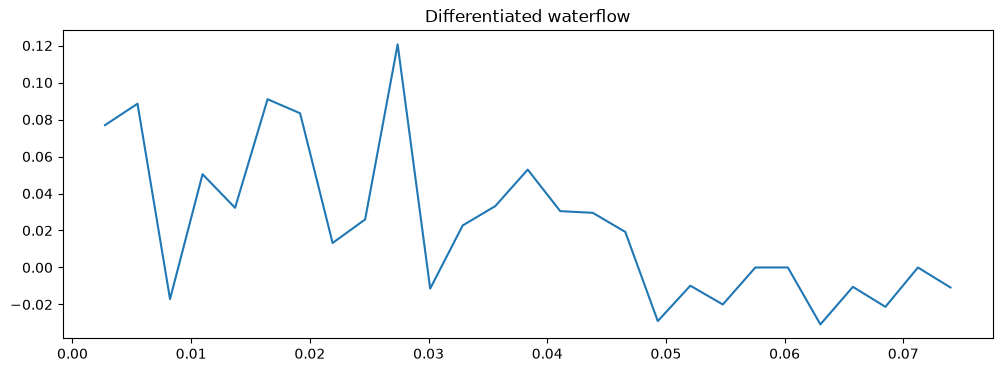

In [50]:
four_weeks = 7 * 4
two_weeks = 7 * 2
model_set = log_waterflow[:four_weeks]
validation_set = log_waterflow[four_weeks:four_weeks + two_weeks]


nabla_1 = [1, -1]
nabla_log_model_set = scipy.signal.lfilter(nabla_1, [1], model_set)[1:]
nabla_log_val_set = scipy.signal.lfilter(nabla_1, [1], validation_set)[1:]
nabla_log_time = project_data.time[1:four_weeks]

plt.figure(figsize=(12, 4))
plt.plot(nabla_log_time, nabla_log_model_set)
plt.title("Differentiated waterflow")

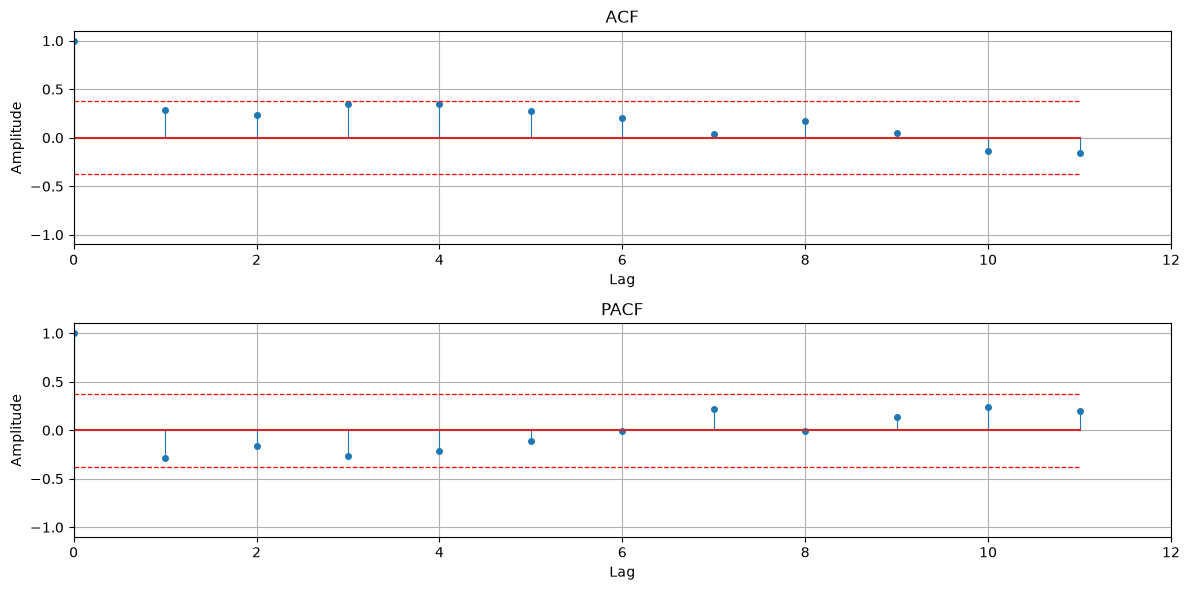

In [51]:
plotACFnPACF(nabla_log_model_set)

Hmm, we do not have any ACF or PACF coefficients that appear significant, which means we have essentially obtained a form of differentiated naive model where we are predicting that the next value of the differentiated series is simply the same as the previous value.

Let's test it, with the presumption that the result will be very bad

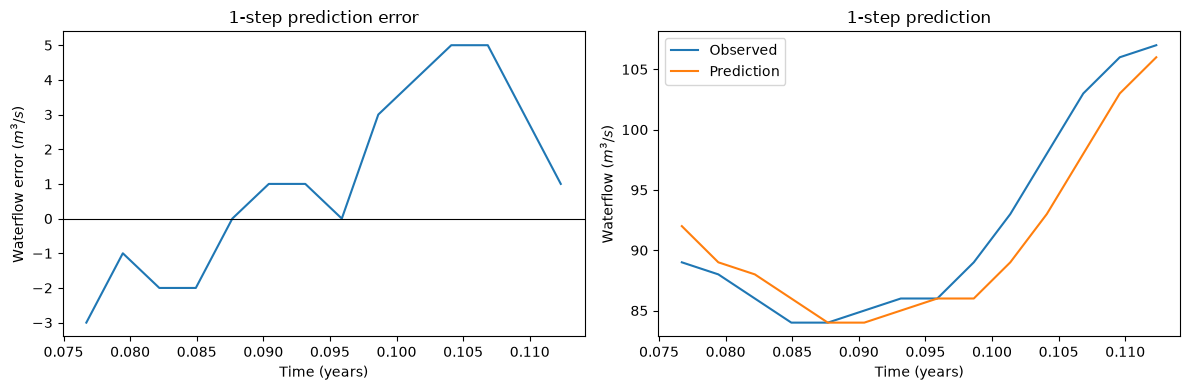

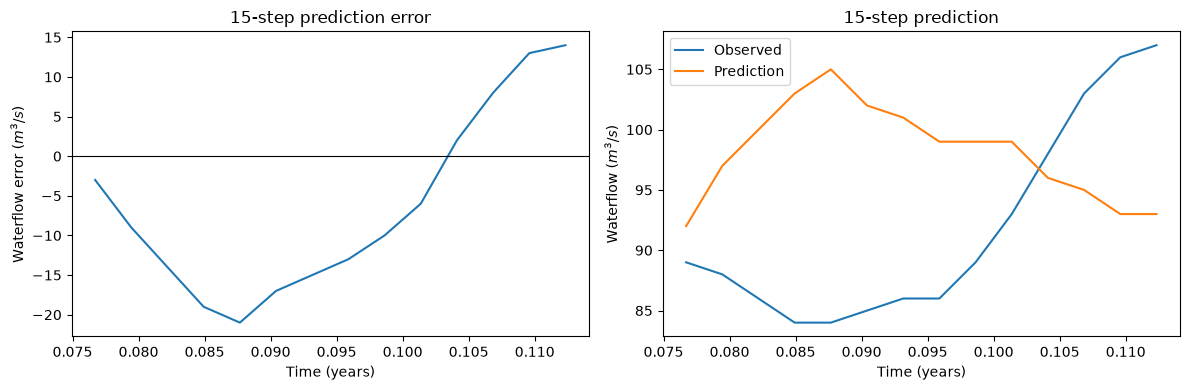

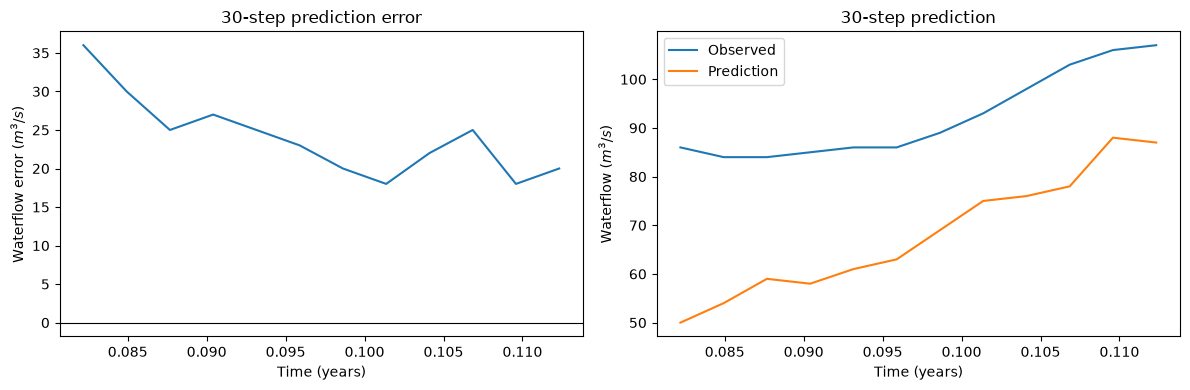

In [66]:
validation_end = four_weeks + two_weeks

for k in (1, 15, 30):
    # Validation targets for which an observation at t-k exists.
    target_idx = np.arange(max(four_weeks, k), validation_end)

    # Your model predicts zero future changes in log-waterflow.
    predicted_log = log_waterflow[target_idx - k]
    predicted = np.exp(predicted_log)

    observed = project_data.waterflow[target_idx]
    error = observed - predicted
    time = project_data.time[target_idx]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(time, error)
    ax1.axhline(0, color="black", linewidth=0.8)
    ax1.set_title(f"{k}-step prediction error")
    ax1.set_ylabel("Waterflow error ($m^3/s$)")

    ax2.plot(time, observed, label="Observed")
    ax2.plot(time, predicted, label="Prediction")
    ax2.set_title(f"{k}-step prediction")
    ax2.set_ylabel("Waterflow ($m^3/s$)")
    ax2.legend()

    for ax in (ax1, ax2):
        ax.set_xlabel("Time (years)")

    plt.tight_layout()

The fact that the prediction looks the same for all three time lags is expected.